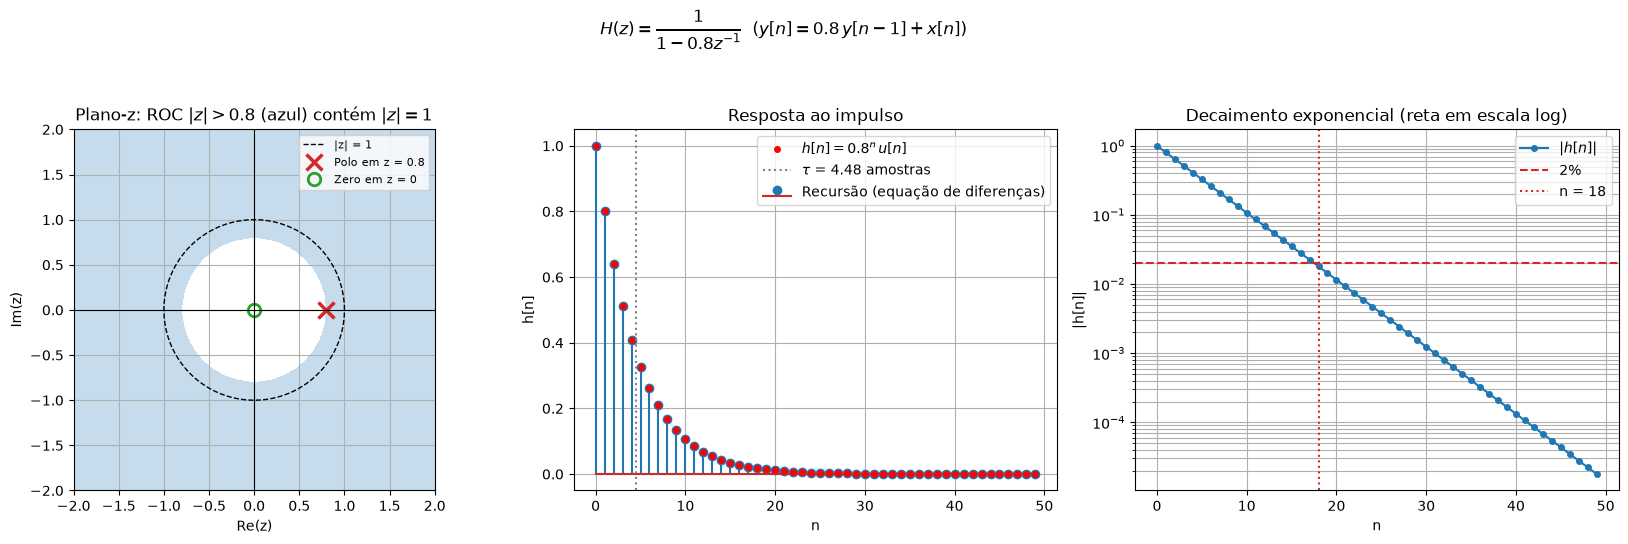

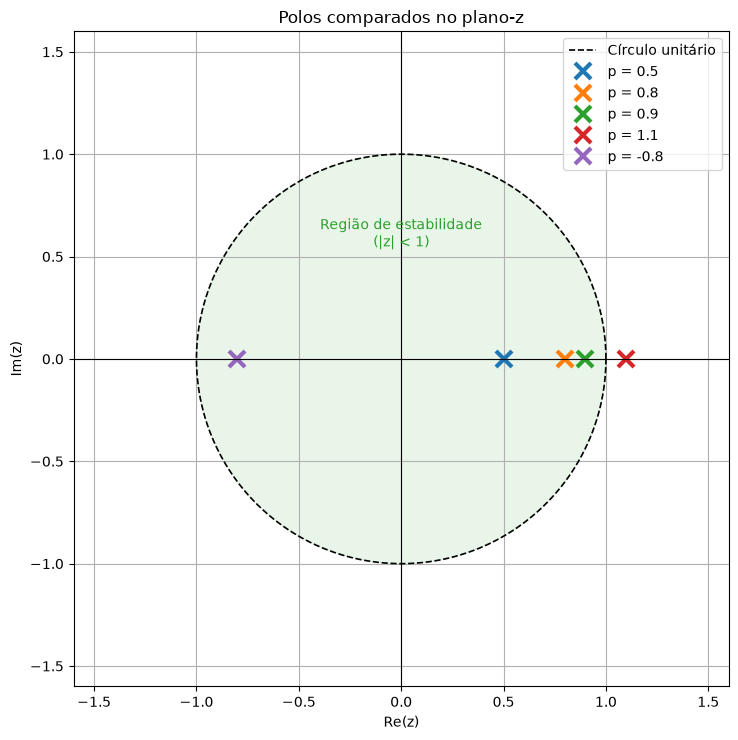

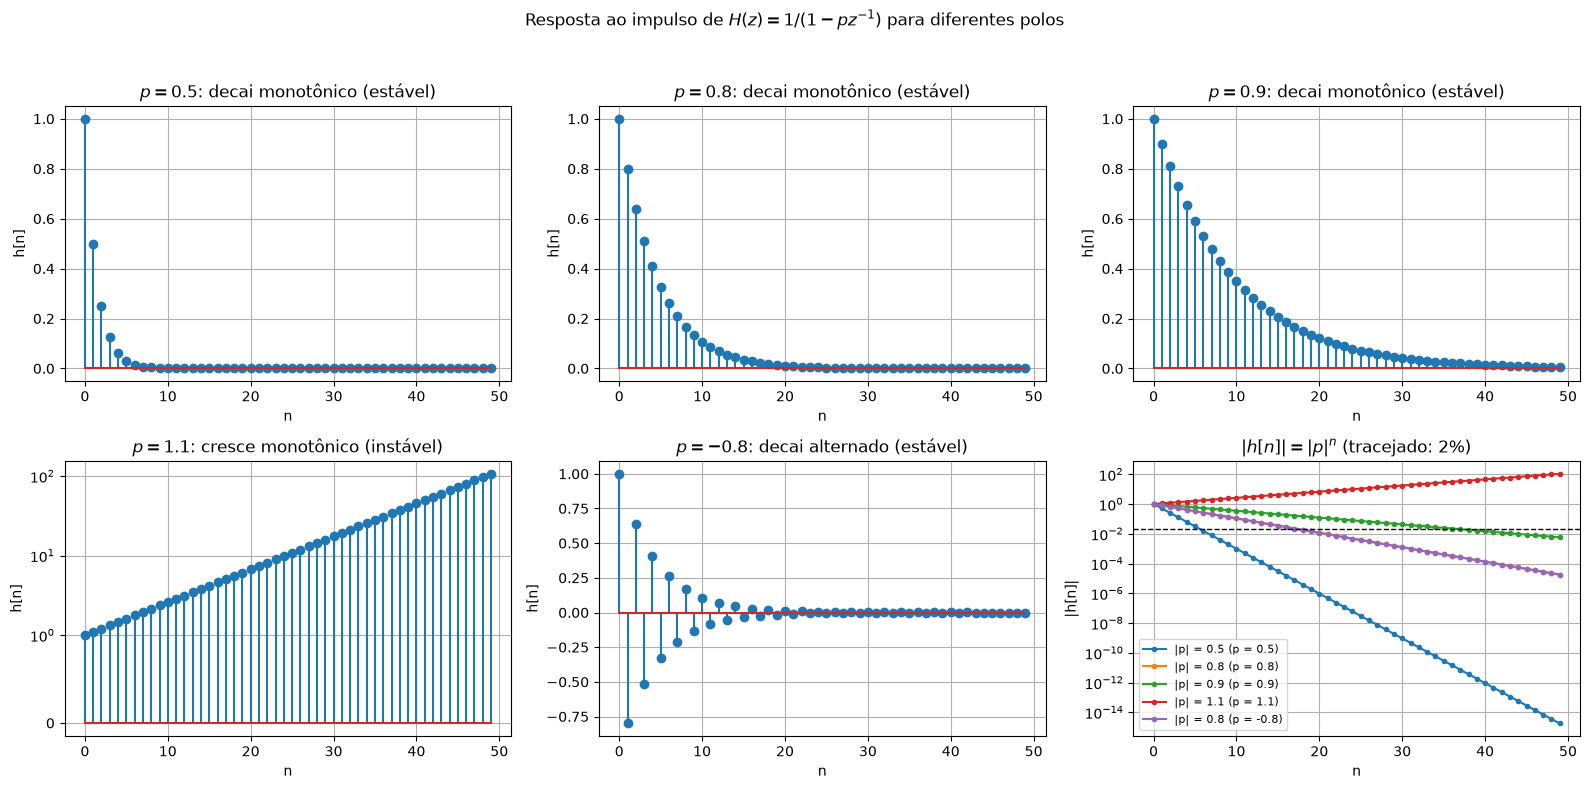

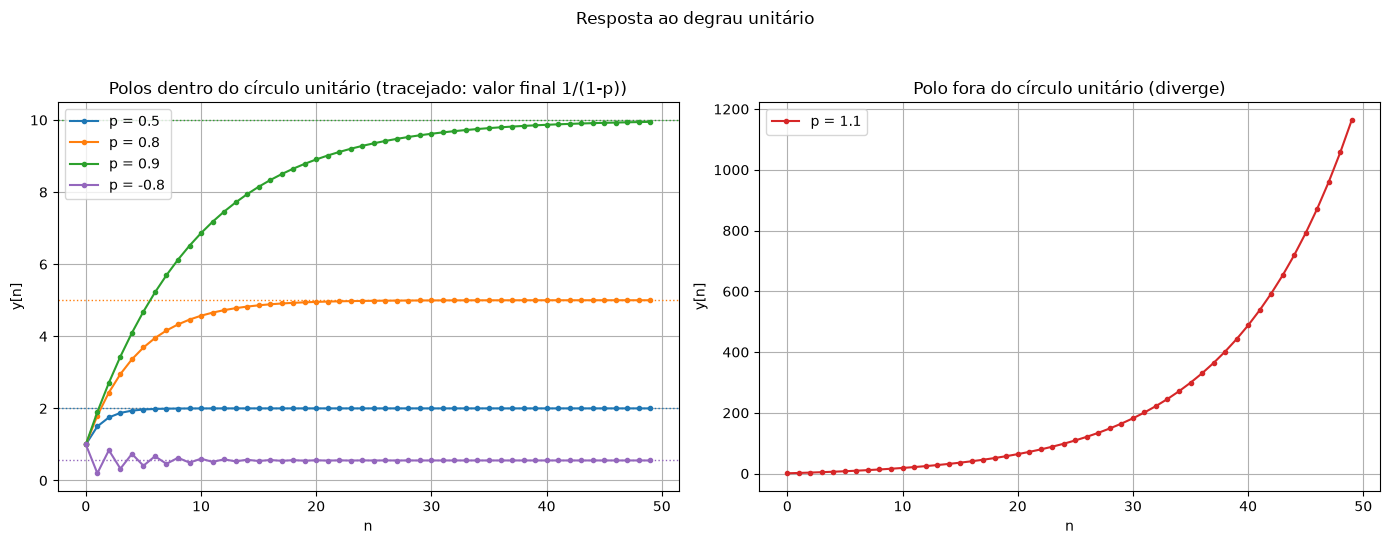

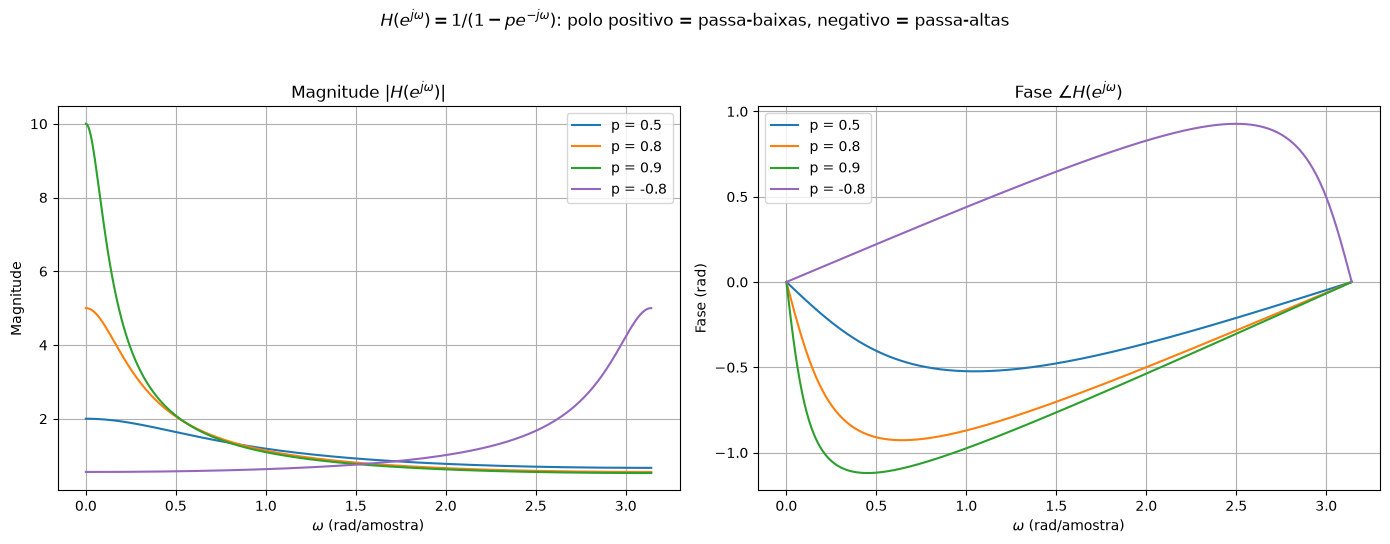

FUNÇÃO DE TRANSFERÊNCIA DISCRETA: H(z) = 1 / (1 - p z^-1)
Equação de diferenças: y[n] = p y[n-1] + x[n]
Resposta ao impulso:   h[n] = p^n u[n]

  Polo    |p|   Estabilidade         Comportamento  tau (amostras)   n (2%)     H(1)    sum|h| (200)  |h| decresce
  0.50   0.50        ESTÁVEL      decai monotônico            1.44        6    2.000               2           sim
  0.80   0.80        ESTÁVEL      decai monotônico            4.48       18    5.000               5           sim
  0.90   0.90        ESTÁVEL      decai monotônico            9.49       38   10.000              10           sim
  1.10   1.10       INSTÁVEL     cresce monotônico               -        -        -       1.899e+09           não
 -0.80   0.80        ESTÁVEL       decai alternado            4.48       18    0.556               5           sim

(tau: |p|^tau = 1/e;  n (2%): primeira amostra com |h[n]| < 0.02;
 H(1) = ganho em regime permanente, definido apenas para sistemas estáveis.)


Verificações numéric

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURAÇÕES DA SIMULAÇÃO
# ============================================================

P_REF = 0.8                                  # Polo do sistema de referência
lista_polos = [0.5, 0.8, 0.9, 1.1, -0.8]     # Polos comparados

cores = {0.5: "C0", 0.8: "C1", 0.9: "C2", 1.1: "C3", -0.8: "C4"}

N = 50                                       # Amostras exibidas nos gráficos
n = np.arange(N)                             # Índices das amostras

N_LONGO = 400                                # Amostras usadas nas somas de verificação
n_longo = np.arange(N_LONGO)

LIMIAR = 0.02                                # Critério de acomodação (2%)


# ============================================================
# 2. MODELAGEM DO SISTEMA DISCRETO
# ============================================================

def filtrar(num, den, x):
    """
    Resolve a equação de diferenças recursivamente:

    y[n] = (1/a0) * ( sum(b_k x[n-k]) - sum(a_k y[n-k], k >= 1) )

    Para y[n] = p*y[n-1] + x[n]:  num = [1],  den = [1, -p]
    """

    y = np.zeros(len(x))

    for i in range(len(x)):
        acumulado = 0.0

        for k, bk in enumerate(num):
            if i - k >= 0:
                acumulado += bk * x[i - k]

        for k in range(1, len(den)):
            if i - k >= 0:
                acumulado -= den[k] * y[i - k]

        y[i] = acumulado / den[0]

    return y


def impulso(N):
    """
    Impulso unitário delta[n] com N amostras.
    """

    x = np.zeros(N)
    x[0] = 1.0

    return x


def degrau(N):
    """
    Degrau unitário u[n] com N amostras.
    """

    return np.ones(N)


def sistema(p):
    """
    Coeficientes de H(z) = 1 / (1 - p z^-1), isto é,
    da equação y[n] = p*y[n-1] + x[n].
    """

    return np.array([1.0]), np.array([1.0, -p])


def h_analitico(n, p):
    """
    Transformada-Z inversa (sistema causal):

    h[n] = p^n u[n]
    """

    return (p ** n.astype(float)) * (n >= 0)


def degrau_analitico(n, p):
    """
    Resposta ao degrau (soma geométrica de h[n]):

    y[n] = (1 - p^(n+1)) / (1 - p)
    """

    return (1 - p ** (n.astype(float) + 1)) / (1 - p)


def H_z(z, p):
    """
    H(z) = 1 / (1 - p z^-1)
    """

    return 1 / (1 - p / z)


def classificar_estabilidade(p, tol=1e-9):
    """
    Sistema causal: estável se o polo está dentro do círculo unitário
    (a ROC |z| > |p| contém |z| = 1).
    """

    if abs(p) > 1 + tol:
        return "INSTÁVEL"

    if abs(p) >= 1 - tol:
        return "MARGINAL"

    return "ESTÁVEL"


def comportamento(p):
    """
    Descrição do comportamento da resposta ao impulso.
    """

    if abs(p) > 1:
        return "cresce" + (" alternado" if p < 0 else " monotônico")

    if abs(p) == 1:
        return "não decai"

    return "decai" + (" alternado" if p < 0 else " monotônico")


# ============================================================
# 3. SISTEMA DE REFERÊNCIA: y[n] = 0.8 y[n-1] + x[n]
# ============================================================

num_ref, den_ref = sistema(P_REF)

h_ref = filtrar(num_ref, den_ref, impulso(N))

# Constante de tempo (amostras): |p|^tau = e^-1  ->  tau = -1/ln|p|
tau_ref = -1 / np.log(abs(P_REF))

# Primeira amostra em que |h[n]| fica abaixo de 2%
n_acomod_ref = int(np.argmax(np.abs(h_ref) < LIMIAR))

fig, eixos = plt.subplots(1, 3, figsize=(17, 5.5))

# --- (a) Polo no plano-z
theta = np.linspace(0, 2 * np.pi, 400)
g = np.linspace(-2, 2, 500)
Xg, Yg = np.meshgrid(g, g)
modulo = np.hypot(Xg, Yg)

eixos[0].contourf(Xg, Yg, (modulo > abs(P_REF)).astype(float),
                  levels=[0.5, 1.5], colors=["tab:blue"], alpha=0.25)
eixos[0].plot(np.cos(theta), np.sin(theta), "k--", linewidth=1, label="|z| = 1")
eixos[0].plot([P_REF], [0], "x", color="tab:red", markersize=11, markeredgewidth=2.5,
              label=f"Polo em z = {P_REF}")
eixos[0].plot([0], [0], "o", color="tab:green", markersize=9, markerfacecolor="none",
              markeredgewidth=2, label="Zero em z = 0")

eixos[0].axhline(0, color="k", linewidth=0.8)
eixos[0].axvline(0, color="k", linewidth=0.8)
eixos[0].set_aspect("equal")
eixos[0].set_xlim(-2, 2)
eixos[0].set_ylim(-2, 2)
eixos[0].set_title(r"Plano-z: ROC $|z|>0.8$ (azul) contém $|z|=1$")
eixos[0].set_xlabel("Re(z)")
eixos[0].set_ylabel("Im(z)")
eixos[0].legend(loc="upper right", fontsize=8)
eixos[0].grid(True)

# --- (b) Resposta ao impulso
eixos[1].stem(n, h_ref, label="Recursão (equação de diferenças)")
eixos[1].plot(n, h_analitico(n, P_REF), "r.", markersize=8, label=r"$h[n]=0.8^n\,u[n]$")
eixos[1].axvline(tau_ref, color="gray", linestyle=":", label=rf"$\tau$ = {tau_ref:.2f} amostras")
eixos[1].set_title("Resposta ao impulso")
eixos[1].set_xlabel("n")
eixos[1].set_ylabel("h[n]")
eixos[1].legend()
eixos[1].grid(True)

# --- (c) Decaimento em escala logarítmica
eixos[2].semilogy(n, np.abs(h_ref), "o-", markersize=4, label=r"$|h[n]|$")
eixos[2].axhline(LIMIAR, color="tab:red", linestyle="--", label="2%")
eixos[2].axvline(n_acomod_ref, color="tab:red", linestyle=":", label=f"n = {n_acomod_ref}")
eixos[2].set_title("Decaimento exponencial (reta em escala log)")
eixos[2].set_xlabel("n")
eixos[2].set_ylabel("|h[n]|")
eixos[2].legend()
eixos[2].grid(True, which="both")

plt.suptitle(r"$H(z)=\dfrac{1}{1-0.8z^{-1}}$  ($y[n]=0.8\,y[n-1]+x[n]$)")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


# ============================================================
# 4. COMPARAÇÃO: POLOS NO PLANO-z
# ============================================================

plt.figure(figsize=(8, 7.5))

eixo = plt.gca()

eixo.fill(np.cos(theta), np.sin(theta), color="tab:green", alpha=0.1)
eixo.plot(np.cos(theta), np.sin(theta), "k--", linewidth=1.2, label="Círculo unitário")

for p in lista_polos:
    eixo.plot([p], [0], "x", color=cores[p], markersize=12, markeredgewidth=3, label=f"p = {p:g}")

eixo.text(0, 0.55, "Região de estabilidade\n(|z| < 1)", ha="center", color="tab:green")

eixo.axhline(0, color="k", linewidth=0.8)
eixo.axvline(0, color="k", linewidth=0.8)

eixo.set_aspect("equal")
eixo.set_xlim(-1.6, 1.6)
eixo.set_ylim(-1.6, 1.6)

eixo.set_title("Polos comparados no plano-z")
eixo.set_xlabel("Re(z)")
eixo.set_ylabel("Im(z)")

eixo.legend(loc="upper right")
eixo.grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 5. COMPARAÇÃO: RESPOSTAS AO IMPULSO
# ============================================================

fig, eixos = plt.subplots(2, 3, figsize=(16, 8))

for eixo, p in zip(eixos.ravel()[:5], lista_polos):
    num, den = sistema(p)
    h = filtrar(num, den, impulso(N))

    eixo.stem(n, h)
    eixo.set_title(rf"$p={p:g}$: {comportamento(p)} ({classificar_estabilidade(p).lower()})")
    eixo.set_xlabel("n")
    eixo.set_ylabel("h[n]")
    eixo.grid(True)

    if abs(p) > 1:
        eixo.set_yscale("symlog", linthresh=1)

# Último painel: módulos sobrepostos
eixo = eixos.ravel()[5]

for p in lista_polos:
    eixo.semilogy(n, np.abs(p) ** n.astype(float), "o-", markersize=3,
                  color=cores[p], label=f"|p| = {abs(p):g} (p = {p:g})")

eixo.axhline(LIMIAR, color="k", linestyle="--", linewidth=1)
eixo.set_title(r"$|h[n]|=|p|^n$ (tracejado: 2%)")
eixo.set_xlabel("n")
eixo.set_ylabel("|h[n]|")
eixo.legend(fontsize=8)
eixo.grid(True, which="both")

plt.suptitle(r"Resposta ao impulso de $H(z)=1/(1-pz^{-1})$ para diferentes polos")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# ============================================================
# 6. COMPARAÇÃO: RESPOSTAS AO DEGRAU
# ============================================================

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

for p in lista_polos:
    num, den = sistema(p)
    y = filtrar(num, den, degrau(N))

    if abs(p) < 1:
        eixos[0].plot(n, y, "o-", markersize=3, color=cores[p], label=f"p = {p:g}")
        eixos[0].axhline(1 / (1 - p), color=cores[p], linestyle=":", linewidth=1)
    else:
        eixos[1].plot(n, y, "o-", markersize=3, color=cores[p], label=f"p = {p:g}")

eixos[0].set_title("Polos dentro do círculo unitário (tracejado: valor final 1/(1-p))")
eixos[1].set_title("Polo fora do círculo unitário (diverge)")

for eixo in eixos:
    eixo.set_xlabel("n")
    eixo.set_ylabel("y[n]")
    eixo.legend()
    eixo.grid(True)

plt.suptitle("Resposta ao degrau unitário")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


# ============================================================
# 7. COMPARAÇÃO: RESPOSTA EM FREQUÊNCIA (POLOS ESTÁVEIS)
# ============================================================

omega = np.linspace(0, np.pi, 500)

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

for p in lista_polos:
    if abs(p) >= 1:
        continue

    H = 1 / (1 - p * np.exp(-1j * omega))

    eixos[0].plot(omega, np.abs(H), color=cores[p], label=f"p = {p:g}")
    eixos[1].plot(omega, np.angle(H), color=cores[p], label=f"p = {p:g}")

eixos[0].set_title(r"Magnitude $|H(e^{j\omega})|$")
eixos[0].set_ylabel("Magnitude")

eixos[1].set_title(r"Fase $\angle H(e^{j\omega})$")
eixos[1].set_ylabel("Fase (rad)")

for eixo in eixos:
    eixo.set_xlabel(r"$\omega$ (rad/amostra)")
    eixo.legend()
    eixo.grid(True)

plt.suptitle(r"$H(e^{j\omega})=1/(1-pe^{-j\omega})$: polo positivo = passa-baixas, negativo = passa-altas")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


# ============================================================
# 8. RESULTADOS: COMPARAÇÃO DOS POLOS
# ============================================================

print("FUNÇÃO DE TRANSFERÊNCIA DISCRETA: H(z) = 1 / (1 - p z^-1)")
print("=" * 112)
print("Equação de diferenças: y[n] = p y[n-1] + x[n]")
print("Resposta ao impulso:   h[n] = p^n u[n]")

print(f"\n{'Polo':>6}{'|p|':>7}{'Estabilidade':>15}{'Comportamento':>22}{'tau (amostras)':>16}"
      f"{'n (2%)':>9}{'H(1)':>9}{'sum|h| (200)':>16}{'|h| decresce':>14}")

n_200 = np.arange(200)

for p in lista_polos:
    num, den = sistema(p)
    h = filtrar(num, den, impulso(200))

    classe = classificar_estabilidade(p)
    decresce = bool(np.all(np.diff(np.abs(h)) < 0))

    if abs(p) < 1:
        tau = -1 / np.log(abs(p))
        n_acomod = int(np.argmax(np.abs(h) < LIMIAR))

        txt_tau = f"{tau:16.2f}"
        txt_n = f"{n_acomod:9d}"
        txt_H1 = f"{1 / (1 - p):9.3f}"
    else:
        txt_tau = f"{'-':>16}"
        txt_n = f"{'-':>9}"
        txt_H1 = f"{'-':>9}"

    print(f"{p:6.2f}{abs(p):7.2f}{classe:>15}{comportamento(p):>22}{txt_tau}{txt_n}{txt_H1}"
          f"{np.sum(np.abs(h)):16.4g}{('sim' if decresce else 'não'):>14}")

print("\n(tau: |p|^tau = 1/e;  n (2%): primeira amostra com |h[n]| < 0.02;")
print(" H(1) = ganho em regime permanente, definido apenas para sistemas estáveis.)")


# ============================================================
# 9. VERIFICAÇÕES NUMÉRICAS
# ============================================================

print("\n\nVerificações numéricas")
print("=" * 100)
print(f"{'Polo':>6}{'h: recursão x analítico':>26}{'degrau: recursão x fechada':>29}"
      f"{'H(z) = Y/X em z0':>22}{'H(e^jw) x DTFT de h':>22}")

# Entrada de teste de duração finita, para verificar H(z) = Y(z)/X(z)
x_teste = np.zeros(N_LONGO)
x_teste[:4] = [1.0, 2.0, -1.0, 0.5]

for p in lista_polos:
    num, den = sistema(p)

    # Resposta ao impulso
    h_rec = filtrar(num, den, impulso(N))
    erro_h = np.max(np.abs(h_rec - h_analitico(n, p)))

    # Resposta ao degrau
    y_rec = filtrar(num, den, degrau(N))
    erro_y = np.max(np.abs(y_rec - degrau_analitico(n, p)) / np.maximum(1, np.abs(y_rec)))

    # H(z) = Y(z) / X(z) em um ponto dentro da ROC
    z0 = 1.5 * abs(p) * np.exp(0.7j)

    y_teste = filtrar(num, den, x_teste)
    Y = np.sum(y_teste * z0 ** (-n_longo.astype(float)))
    X = np.sum(x_teste * z0 ** (-n_longo.astype(float)))

    erro_H = np.abs(Y / X - H_z(z0, p))

    # Resposta em frequência (apenas para sistemas estáveis)
    if abs(p) < 1:
        omega_v = np.linspace(0, np.pi, 100)
        h_longo = filtrar(num, den, impulso(N_LONGO))

        dtft = np.array([np.sum(h_longo * np.exp(-1j * w * n_longo)) for w in omega_v])
        erro_f = np.max(np.abs(dtft - 1 / (1 - p * np.exp(-1j * omega_v))))

        txt_f = f"{erro_f:22.3e}"
    else:
        txt_f = f"{'não existe':>22}"

    print(f"{p:6.2f}{erro_h:26.3e}{erro_y:29.3e}{erro_H:22.3e}{txt_f}")


# ============================================================
# 10. CONCLUSÕES
# ============================================================

print("\n\nCONCLUSÕES")
print("=" * 70)
print("H(z) = Y(z)/X(z) = 1/(1 - p z^-1): um polo em z = p e um zero em z = 0.")
print("A resposta ao impulso h[n] = p^n u[n] depende apenas da posição do polo:")
print("0 < p < 1  : decai de forma monotônica; quanto mais perto de 1, mais lento")
print("                 (tau = -1/ln|p|: 4.5 amostras para 0.8, 9.5 para 0.9).")
print("-1 < p < 0 : decai com sinal alternado (oscilação na frequência de Nyquist).")
print("|p| = 1    : não decai (marginalmente estável).")
print("|p| > 1    : cresce exponencialmente (instável).")
print("Estabilidade: o sistema causal é estável se, e somente se, |p| < 1, isto é,")
print("a ROC |z| > |p| contém o círculo unitário (sum|h[n]| finita).")
print("Em frequência: p > 0 é passa-baixas (ganho máximo 1/(1-p) em w = 0) e")
print("p < 0 é passa-altas (ganho máximo 1/(1-|p|) em w = pi).")

print("\nSimulação concluída!")